# Document-type classifier — MobileNetV2 (invoice vs bill of exchange)

Routes each uploaded document to the matching extraction model. Runs on CPU in under 50 ms.

| Setting | Value |
|---|---|
| Backbone | MobileNetV2 pre-trained on ImageNet |
| Head | Dropout 0.4 → Linear 1280→256 → ReLU → Dropout 0.3 → Linear 256→2 |
| Parameters | 2,552,322 |
| Optimiser | Adam, LR 1e-3 then 1e-4 after unfreezing, ReduceLROnPlateau (factor 0.3, patience 3) |
| Early stopping | patience 10 (best epoch 16, stopped at epoch 26) |

**Results on 322 test images (161 invoices, 161 bills of exchange):** accuracy **99.69 %** (321 / 322), ROC-AUC 1.00.
The single error is a poorly lit, oblique invoice classified with 75.4 % confidence; a confidence threshold of 90 %
would send it to manual review.

> **Limitation.** The test split was also used for early stopping and model selection.

> **Environment.** Kaggle notebook, NVIDIA Tesla T4 (16 GB), Python 3.12. GLM-OCR requires the development
> version of `transformers` (installed in the first cell). After the first cell, **restart the kernel**.
>
> **Data.** The datasets are private (client documents) and are not distributed. Paths of the form
> `/kaggle/input/datasets/<KAGGLE_USER>/...` refer to private Kaggle datasets and must be adapted.

> **Anonymisation.** Outputs containing client or supplier data and document images were removed.
> Only aggregate metrics are kept.

## 1. Imports and configuration

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
import numpy as np
import os, glob, zipfile
from PIL import Image
from copy import deepcopy
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

## 2. Paths and hyper-parameters

In [ ]:
DATA_DIR  = "/kaggle/input/datasets/<KAGGLE_USER>/classification2/dataset_split"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")
SAVE_DIR  = "/kaggle/working"
SAVE_PATH = os.path.join(SAVE_DIR, "best_model.pth")
ZIP_PATH  = os.path.join(SAVE_DIR, "best_model_bundle.zip")

BATCH_SIZE  = 32
EPOCHS      = EPOCHS = 100
LR_INIT     = 1e-3
LR_MIN      = 1e-7
PATIENCE    = 10
OVERFIT_GAP = 15.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)

Device : cuda


## 3. Pre-processing and augmentation

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(5),
    transforms.ColorJitter(contrast=0.3, brightness=0.2),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

print("Transforms définis ✓")

Transforms définis ✓


## 4. Dataset

In [ ]:
class DocDataset(Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform
        self.samples   = []
        self.classes   = ["factures", "traites"]

        for label_idx, classe in enumerate(self.classes):
            for subdir in ["augmented", "generated", "real"]:
                pattern = os.path.join(root, classe, subdir, "*.*")
                for path in glob.glob(pattern):
                    if path.lower().endswith((".jpg",".jpeg",".png",".bmp")):
                        self.samples.append((path, label_idx))

        counts = [sum(1 for _, l in self.samples if l == i)
                  for i in range(2)]
        print(f"[{root.split('/')[-1]}]  "
              f"factures={counts[0]}  "
              f"traites={counts[1]}  "
              f"total={len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


train_dataset = DocDataset(TRAIN_DIR, transform=train_transform)
test_dataset  = DocDataset(TEST_DIR,  transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"\nTrain : {len(train_loader)} batches")
print(f"Test  : {len(test_loader)}  batches")

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (path, label) in zip(axes.flatten(),
                              train_dataset.samples[:8]):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{'facture' if label==0 else 'traite'}\n"
                 f"{os.path.basename(path)[:18]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Aperçu TRAIN", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Model — MobileNetV2 with a custom head

In [ ]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze backbone entier
for param in model.features.parameters():
    param.requires_grad = False

# Classifier avec Dropout anti-overfitting
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(256, 2)
)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=LR_INIT,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.3,
    patience=3, min_lr=LR_MIN
)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters()
                if p.requires_grad)
print(f"Paramètres totaux       : {total:,}")
print(f"Paramètres entraînables : {trainable:,}")
print(f"Backbone gelé           : {total - trainable:,}")

Paramètres totaux       : 2,552,322
Paramètres entraînables : 328,450
Backbone gelé           : 2,223,872


## 6. Training
Two stages: frozen backbone, then the last three backbone blocks are unfrozen with a lower learning rate. ReduceLROnPlateau and early stopping (patience 10).

In [ ]:
# ── Fonctions ─────────────────────────────────────────────────────

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if train:
                optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()
    return total_loss / len(loader), 100.0 * correct / total


def unfreeze_backbone(n_blocks=3):
    global optimizer, scheduler
    for param in model.features[-n_blocks:].parameters():
        param.requires_grad = True
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR_INIT / 10, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.3,
        patience=3, min_lr=LR_MIN
    )
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  → Backbone dégelé ({n_blocks} blocs) | "
          f"LR={LR_INIT/10:.1e} | trainable={n:,}")


def save_bundle(epoch, val_acc):
    """Sauvegarde pth + info dans un zip — SANS ONNX."""
    info_path = os.path.join(SAVE_DIR, "model_info.txt")
    with open(info_path, "w") as f:
        f.write(f"Modele  : MobileNetV2\n")
        f.write(f"Epoch   : {epoch}\n")
        f.write(f"Val Acc : {val_acc:.2f}%\n")
        f.write(f"Classes : factures=0  traites=1\n")
        f.write(f"Input   : 224x224 RGB normalise ImageNet\n")
    with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(SAVE_PATH, "best_model.pth")
        zf.write(info_path, "model_info.txt")
    size_mb = os.path.getsize(ZIP_PATH) / 1e6
    print(f"  📦 ZIP → {ZIP_PATH} ({size_mb:.1f} MB)")


print("Fonctions définies ✓")

# ── Entraînement ──────────────────────────────────────────────────

history = {"train_loss": [], "val_loss": [],
           "train_acc":  [], "val_acc":  [], "lr": []}

best_val_loss     = float("inf")
best_val_acc      = 0.0
best_model_wts    = deepcopy(model.state_dict())
patience_counter  = 0
backbone_unfrozen = False

print(f"{'Epoch':>6} {'Train Loss':>11} {'Val Loss':>10} "
      f"{'Train Acc':>10} {'Val Acc':>9} {'LR':>10}  Status")
print("─" * 92)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss,   val_acc   = run_epoch(test_loader,  train=False)

    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    gap    = train_acc - val_acc
    status = f"⚠ OVERFIT +{gap:.1f}%  " if gap > OVERFIT_GAP else ""

    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        best_val_acc   = val_acc
        best_model_wts = deepcopy(model.state_dict())
        torch.save({
            "epoch":       epoch,
            "model_state": best_model_wts,
            "val_loss":    best_val_loss,
            "val_acc":     best_val_acc,
            "optimizer":   optimizer.state_dict(),
            "history":     history,
            "classes":     ["factures", "traites"],
        }, SAVE_PATH)
        save_bundle(epoch, val_acc)
        status += "✅ saved"
        patience_counter = 0
    else:
        patience_counter += 1
        status += f"patience {patience_counter}/{PATIENCE}"

    print(f"{epoch:>6} {train_loss:>11.4f} {val_loss:>10.4f} "
          f"{train_acc:>9.2f}% {val_acc:>8.2f}% "
          f"{current_lr:>10.2e}  {status}")

    if not backbone_unfrozen and current_lr < LR_INIT * 0.4:
        unfreeze_backbone(n_blocks=3)
        backbone_unfrozen = True

    if patience_counter >= PATIENCE:
        print(f"\n⛔ Early stopping à l'epoch {epoch}")
        break

print(f"\n✅ Meilleur modèle : "
      f"val_loss={best_val_loss:.4f}  "
      f"val_acc={best_val_acc:.2f}%")
model.load_state_dict(best_model_wts)

Fonctions définies ✓
 Epoch  Train Loss   Val Loss  Train Acc   Val Acc         LR  Status
────────────────────────────────────────────────────────────────────────────────────────────
  📦 ZIP → /kaggle/working/best_model_bundle.zip (12.1 MB)
     1      0.1912     0.0565     94.26%    98.45%   1.00e-03  ✅ saved
     2      0.0713     0.0609     97.13%    96.58%   1.00e-03  patience 1/10
  📦 ZIP → /kaggle/working/best_model_bundle.zip (12.0 MB)
     3      0.0835     0.0229     96.65%    99.38%   1.00e-03  ✅ saved
  📦 ZIP → /kaggle/working/best_model_bundle.zip (12.1 MB)
     4      0.0384     0.0228     98.33%    99.38%   1.00e-03  ✅ saved
  📦 ZIP → /kaggle/working/best_model_bundle.zip (12.1 MB)
     5      0.0174     0.0213     99.44%    99.38%   1.00e-03  ✅ saved
  📦 ZIP → /kaggle/working/best_model_bundle.zip (12.1 MB)
     6      0.0270     0.0151     98.65%    99.69%   1.00e-03  ✅ saved
     7      0.0251     0.0328     99.04%    99.07%   1.00e-03  patience 1/10
     8      0.029

<All keys matched successfully>

## 7. Training curves

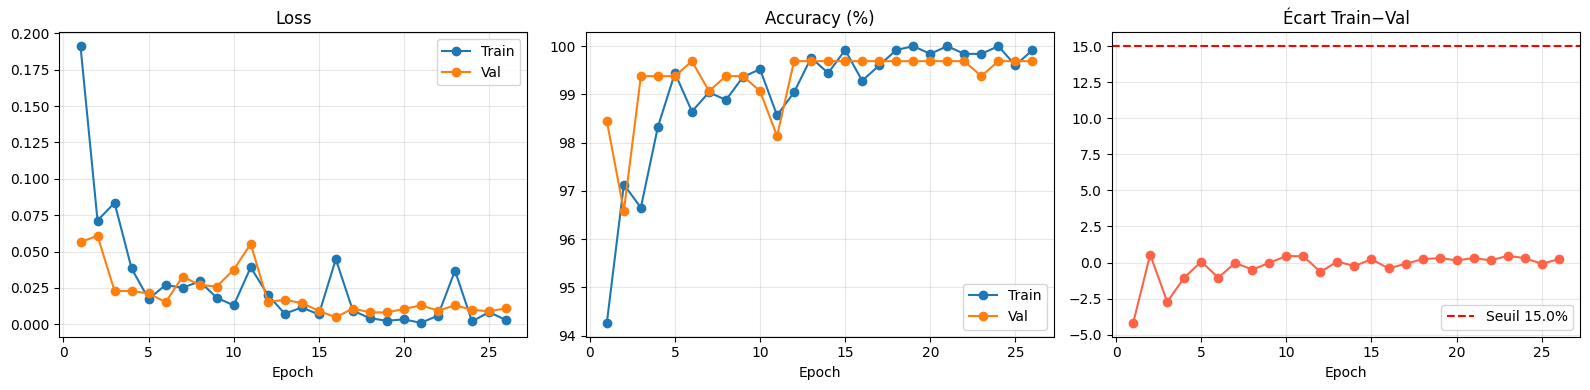

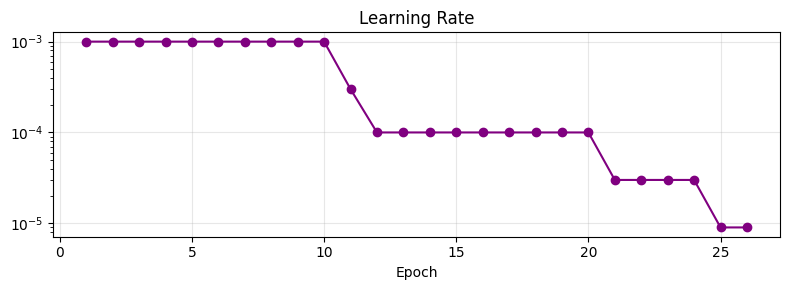

In [ ]:
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(epochs_range, history["train_loss"],
             label="Train", marker='o')
axes[0].plot(epochs_range, history["val_loss"],
             label="Val", marker='o')
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"],
             label="Train", marker='o')
axes[1].plot(epochs_range, history["val_acc"],
             label="Val", marker='o')
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

gap = [t - v for t, v in zip(history["train_acc"],
                               history["val_acc"])]
axes[2].plot(epochs_range, gap, color="tomato", marker='o')
axes[2].axhline(y=OVERFIT_GAP, color="red",
                linestyle="--", label=f"Seuil {OVERFIT_GAP}%")
axes[2].set_title("Écart Train−Val")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Courbe LR
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(epochs_range, history["lr"], marker='o', color="purple")
ax.set_title("Learning Rate")
ax.set_xlabel("Epoch")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluation on the test set

✅ Modèle chargé — epoch=16  val_acc=99.69%

   RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    factures     1.0000    0.9938    0.9969       161
     traites     0.9938    1.0000    0.9969       161

    accuracy                         0.9969       322
   macro avg     0.9969    0.9969    0.9969       322
weighted avg     0.9969    0.9969    0.9969       322

   MÉTRIQUES GLOBALES
  Total images testées : 322
  Correctes            : 321
  Erreurs              : 1
  Accuracy             : 99.6894%
  Taux d'erreur        : 0.3106%

  Confiance moyenne (bonnes prédictions) : 99.91%
  Confiance moyenne (erreurs)            : 75.42%


/tmp/ipykernel_510/3654705868.py:181: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


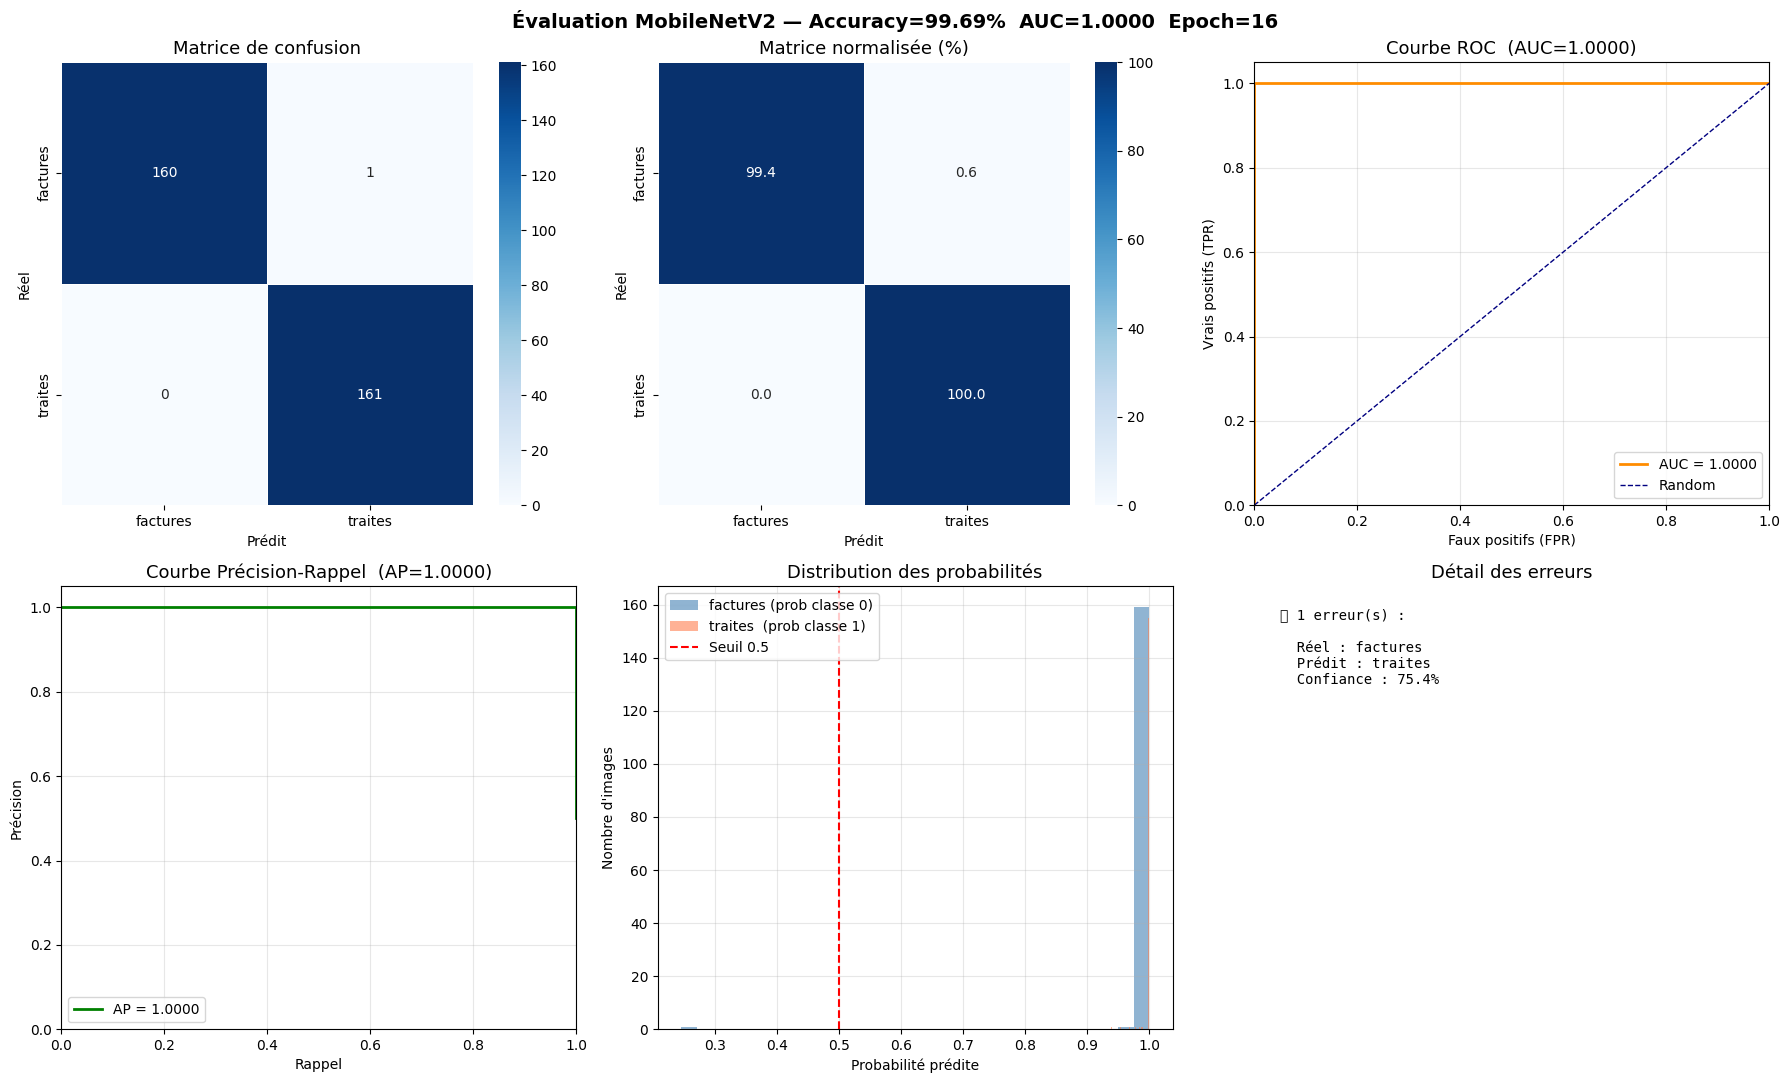


  RÉSUMÉ FINAL
  Modèle    : MobileNetV2
  Epoch     : 16
  Accuracy  : 99.6894%
  AUC-ROC   : 1.0000
  AP        : 1.0000
  Erreurs   : 1 / 322
  ZIP       : /kaggle/working/best_model_bundle.zip
  Taille    : 21.0 MB


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score
)
from torch.nn.functional import softmax

# ── Chargement meilleur modèle ────────────────────────────────────
checkpoint = torch.load(SAVE_PATH)
model.load_state_dict(checkpoint["model_state"])
print(f"✅ Modèle chargé — epoch={checkpoint['epoch']}  "
      f"val_acc={checkpoint['val_acc']:.2f}%\n")

# ── Inférence complète sur le test set ───────────────────────────
model.eval()
all_preds    = []
all_labels   = []
all_probs    = []   # probabilités softmax pour ROC/PR curves
all_paths    = []   # chemins pour afficher les erreurs

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(DEVICE)
        outputs = model(images)
        probs   = softmax(outputs, dim=1)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

CLASSES = ["factures", "traites"]

# ════════════════════════════════════════════════════════════════
# 1. RAPPORT DE CLASSIFICATION
# ════════════════════════════════════════════════════════════════
print("=" * 55)
print("   RAPPORT DE CLASSIFICATION")
print("=" * 55)
print(classification_report(
    all_labels, all_preds,
    target_names=CLASSES,
    digits=4
))

# ════════════════════════════════════════════════════════════════
# 2. MÉTRIQUES GLOBALES
# ════════════════════════════════════════════════════════════════
correct      = (all_preds == all_labels).sum()
total        = len(all_labels)
accuracy     = 100.0 * correct / total
n_errors     = total - correct

print("=" * 55)
print("   MÉTRIQUES GLOBALES")
print("=" * 55)
print(f"  Total images testées : {total}")
print(f"  Correctes            : {correct}")
print(f"  Erreurs              : {n_errors}")
print(f"  Accuracy             : {accuracy:.4f}%")
print(f"  Taux d'erreur        : {100-accuracy:.4f}%")

# Confiance moyenne du modèle
conf_correct = all_probs[np.arange(total), all_preds][all_preds == all_labels]
conf_wrong   = all_probs[np.arange(total), all_preds][all_preds != all_labels]
print(f"\n  Confiance moyenne (bonnes prédictions) : "
      f"{conf_correct.mean()*100:.2f}%")
if len(conf_wrong) > 0:
    print(f"  Confiance moyenne (erreurs)            : "
          f"{conf_wrong.mean()*100:.2f}%")
print("=" * 55)

# ════════════════════════════════════════════════════════════════
# 3. FIGURES
# ════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# ── 3a. Matrice de confusion ──────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            ax=axes[0, 0], linewidths=0.5)
axes[0, 0].set_title("Matrice de confusion", fontsize=13)
axes[0, 0].set_ylabel("Réel")
axes[0, 0].set_xlabel("Prédit")

# ── 3b. Matrice de confusion normalisée (%) ───────────────────
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES,
            ax=axes[0, 1], linewidths=0.5)
axes[0, 1].set_title("Matrice normalisée (%)", fontsize=13)
axes[0, 1].set_ylabel("Réel")
axes[0, 1].set_xlabel("Prédit")

# ── 3c. Courbe ROC ────────────────────────────────────────────
fpr, tpr, _ = roc_curve(all_labels, all_probs[:, 1])
roc_auc     = auc(fpr, tpr)
axes[0, 2].plot(fpr, tpr, color='darkorange', lw=2,
                label=f'AUC = {roc_auc:.4f}')
axes[0, 2].plot([0, 1], [0, 1], color='navy',
                lw=1, linestyle='--', label='Random')
axes[0, 2].set_xlim([0.0, 1.0])
axes[0, 2].set_ylim([0.0, 1.05])
axes[0, 2].set_xlabel('Faux positifs (FPR)')
axes[0, 2].set_ylabel('Vrais positifs (TPR)')
axes[0, 2].set_title(f'Courbe ROC  (AUC={roc_auc:.4f})', fontsize=13)
axes[0, 2].legend(loc="lower right")
axes[0, 2].grid(True, alpha=0.3)

# ── 3d. Courbe Précision-Rappel ───────────────────────────────
precision, recall, _ = precision_recall_curve(
    all_labels, all_probs[:, 1])
ap = average_precision_score(all_labels, all_probs[:, 1])
axes[1, 0].plot(recall, precision, color='green', lw=2,
                label=f'AP = {ap:.4f}')
axes[1, 0].set_xlabel('Rappel')
axes[1, 0].set_ylabel('Précision')
axes[1, 0].set_title(f'Courbe Précision-Rappel  (AP={ap:.4f})',
                     fontsize=13)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xlim([0.0, 1.0])
axes[1, 0].set_ylim([0.0, 1.05])

# ── 3e. Distribution des probabilités ────────────────────────
probs_facture = all_probs[all_labels == 0, 0]
probs_traite  = all_probs[all_labels == 1, 1]
axes[1, 1].hist(probs_facture, bins=30, alpha=0.6,
                color='steelblue', label='factures (prob classe 0)')
axes[1, 1].hist(probs_traite,  bins=30, alpha=0.6,
                color='coral',    label='traites  (prob classe 1)')
axes[1, 1].axvline(x=0.5, color='red', linestyle='--',
                   label='Seuil 0.5')
axes[1, 1].set_xlabel('Probabilité prédite')
axes[1, 1].set_ylabel('Nombre d\'images')
axes[1, 1].set_title('Distribution des probabilités', fontsize=13)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# ── 3f. Erreurs de classification ────────────────────────────
errors_idx = np.where(all_preds != all_labels)[0]
axes[1, 2].axis('off')
if len(errors_idx) == 0:
    axes[1, 2].text(0.5, 0.5,
                    "✅ Zéro erreur\nsur le test set !",
                    ha='center', va='center',
                    fontsize=16, color='green',
                    transform=axes[1, 2].transAxes)
else:
    error_text = f"❌ {len(errors_idx)} erreur(s) :\n\n"
    for i in errors_idx[:10]:
        prob = all_probs[i]
        error_text += (
            f"  Réel : {CLASSES[all_labels[i]]}\n"
            f"  Prédit : {CLASSES[all_preds[i]]}\n"
            f"  Confiance : {prob[all_preds[i]]*100:.1f}%\n\n"
        )
    axes[1, 2].text(0.05, 0.95, error_text,
                    ha='left', va='top',
                    fontsize=10,
                    transform=axes[1, 2].transAxes,
                    family='monospace')
    axes[1, 2].set_title("Détail des erreurs", fontsize=13)

plt.suptitle(
    f"Évaluation MobileNetV2 — "
    f"Accuracy={accuracy:.2f}%  AUC={roc_auc:.4f}  "
    f"Epoch={checkpoint['epoch']}",
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# 4. RÉSUMÉ FINAL
# ════════════════════════════════════════════════════════════════
print(f"\n{'='*55}")
print(f"  RÉSUMÉ FINAL")
print(f"{'='*55}")
print(f"  Modèle    : MobileNetV2")
print(f"  Epoch     : {checkpoint['epoch']}")
print(f"  Accuracy  : {accuracy:.4f}%")
print(f"  AUC-ROC   : {roc_auc:.4f}")
print(f"  AP        : {ap:.4f}")
print(f"  Erreurs   : {n_errors} / {total}")
print(f"  ZIP       : {ZIP_PATH}")
print(f"  Taille    : {os.path.getsize(ZIP_PATH)/1e6:.1f} MB")
print(f"{'='*55}")

## 9. Publishing the model to the Hugging Face Hub
The token is read from Kaggle Secrets.

In [ ]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi
import os

# Récupère le token depuis les secrets Kaggle
hf_token = UserSecretsClient().get_secret("HF_TOKEN")
api = HfApi(token=hf_token)

# ✅ Chemin corrigé
MODEL_PATH = "/kaggle/input/datasets/<KAGGLE_USER>/classificateur-traite-facture/best_model.pth"

# Vérification que le fichier existe bien
assert os.path.isfile(MODEL_PATH), f"❌ Fichier introuvable : {MODEL_PATH}"
print(f"✅ Fichier trouvé — {os.path.getsize(MODEL_PATH)/1e6:.1f} MB")

# Crée le repo si il n'existe pas encore
api.create_repo("Goubaa/mobilenet-classifier",
                repo_type="model",
                exist_ok=True)

# Upload
api.upload_file(
    path_or_fileobj=MODEL_PATH,
    path_in_repo="best_model.pth",
    repo_id="Goubaa/mobilenet-classifier",
)
print("✅ Modèle disponible sur HuggingFace : Goubaa/mobilenet-classifier")

✅ Fichier trouvé — 22.8 MB


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

✅ Modèle disponible sur HuggingFace : Goubaa/mobilenet-classifier
